In [ ]:
#problem-set-2
#sayad alakbarov

In [ ]:
#question1-a
# If the true Bayes decision boundary is linear:
# On the training set, QDA will likely perform better because it is more flexible
# and can adapt closely to the training data, even fitting some noise.
# On the test set, LDA is expected to perform better because it correctly assumes a linear boundary
# and will have lower variance, while QDA may overfit due to its higher flexibility.

In [3]:
# (b)
# If the true Bayes decision boundary is non-linear:
# On the training set, QDA will typically perform better because its flexibility
# allows it to capture complex, non-linear boundaries and fit the data more closely.
# On the test set, QDA is also expected to perform better than LDA
# as long as the sample size is sufficiently large to estimate the parameters accurately.
# However, if the sample size is small, QDA may overfit and LDA could generalize better.

In [4]:
# (c)
# As the sample size n increases, the test prediction accuracy of QDA relative to LDA
# is expected to improve.
# This is because with more data, QDA can estimate its larger number of parameters
# (class-specific covariance matrices) more accurately.
# As a result, its higher flexibility becomes an advantage rather than a source of overfitting,
# allowing QDA to better capture non-linear boundaries and improve relative to LDA.

In [5]:
# (d)
# False.
# Even if QDA is flexible enough to model a linear decision boundary,
# this flexibility comes at the cost of higher variance due to estimating more parameters.
# When the true boundary is linear, LDA is correctly specified and more efficient,
# leading to a lower test error rate on average.
# QDA may overfit the training data and perform worse on unseen test data.

In [8]:
#question2-a
# Given:
# β0 = -6
# β1 = 0.05
# β2 = 1
# X1 = 40 (hours studied)
# X2 = 3.5 (undergrad GPA)
# log(p / (1 - p)) = β0 + β1*X1 + β2*X2
linear_combination = -6 + 0.05 * 40 + 1 * 3.5
import math
p = math.exp(linear_combination) / (1 + math.exp(linear_combination))
print(p)

0.37754066879814546


In [10]:
# (b)
# Given
# β0 = -6
# β1 = 0.05
# β2 = 1
# X2 = 3.5 (undergrad GPA)
# We want to find X1 such that p = 0.5
# log(p / (1 - p)) = β0 + β1*X1 + β2*X2
# For p = 0.5, log(p / (1 - p)) = 0
# 0 = -6 + 0.05*X1 + 1*3.5

X1 = (6 - 3.5) / 0.05
print(X1)

50.0


In [14]:
#question3
# Given:
# Mean for dividend = μ_yes = 10
# Mean for no dividend = μ_no = 0
# Variance = σ² = 36  →  σ = 6
# Prior probabilities:
# P(Yes) = 0.8
# P(No) = 0.2
# Observed X = 4

import math
def normal_pdf(x, mu, sigma):
    return (1 / (math.sqrt(2 * math.pi) * sigma)) * math.exp(-((x - mu) ** 2) / (2 * sigma ** 2))
mu_yes, mu_no = 10, 0
sigma = 6
p_yes = 0.8
p_no = 0.2
x = 4

f_yes = normal_pdf(x, mu_yes, sigma)
f_no = normal_pdf(x, mu_no, sigma)
# P(Yes | X=4) = [f_yes * P(Yes)] / ([f_yes * P(Yes)] + [f_no * P(No)])
posterior_yes = (f_yes * p_yes) / ((f_yes * p_yes) + (f_no * p_no))

print(posterior_yes)

0.7518524532975261


In [ ]:
#question4-a
import pandas as pd

auto = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-Auto.csv")
mpg_median = auto["mpg"].median()
auto["mpg01"] = (auto["mpg"] > mpg_median).astype(int)
print(auto.head())

   Unnamed: 0   mpg  cylinders  displacement  horsepower  weight  \
0           1  18.0          8         307.0         130    3504   
1           2  15.0          8         350.0         165    3693   
2           3  18.0          8         318.0         150    3436   
3           4  16.0          8         304.0         150    3433   
4           5  17.0          8         302.0         140    3449   

   acceleration  year  origin                       name  mpg01  
0          12.0    70       1  chevrolet chevelle malibu      0  
1          11.5    70       1          buick skylark 320      0  
2          11.0    70       1         plymouth satellite      0  
3          12.0    70       1              amc rebel sst      0  
4          10.5    70       1                ford torino      0  


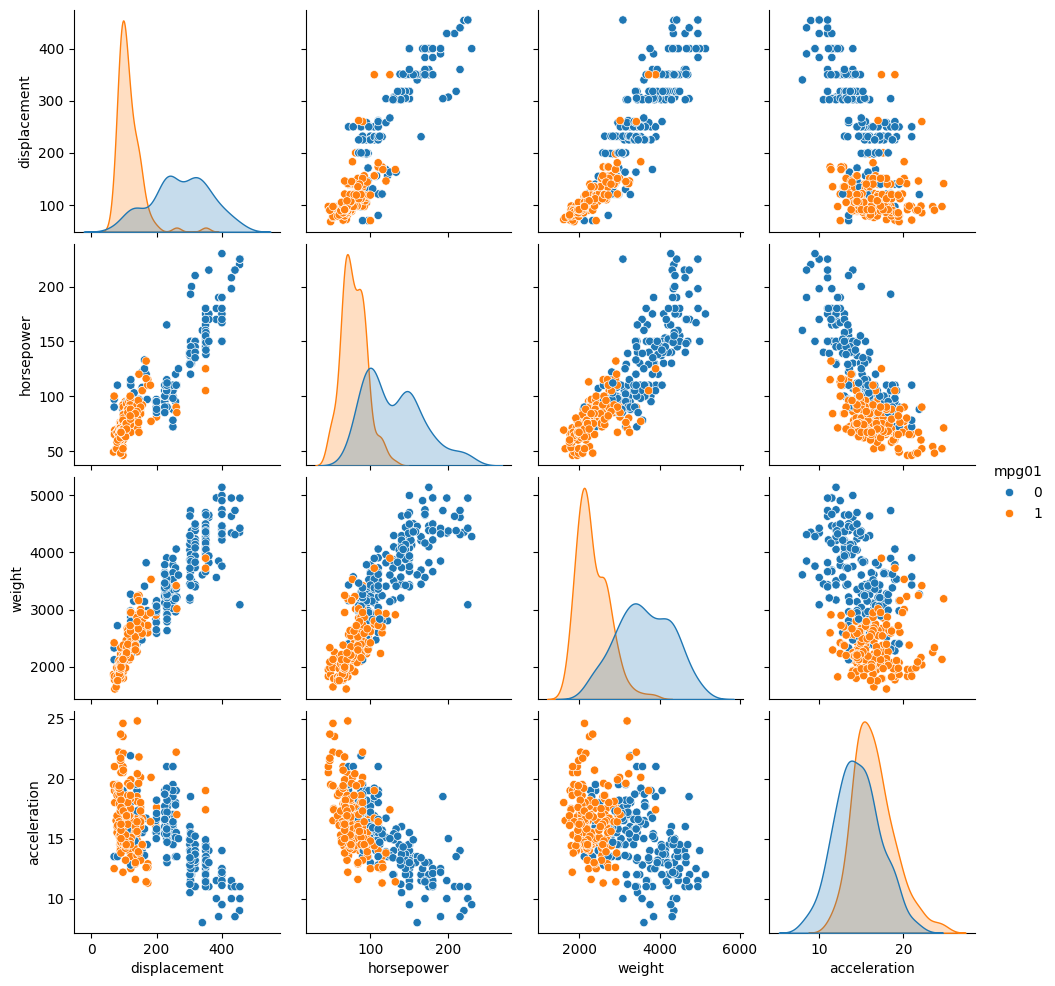

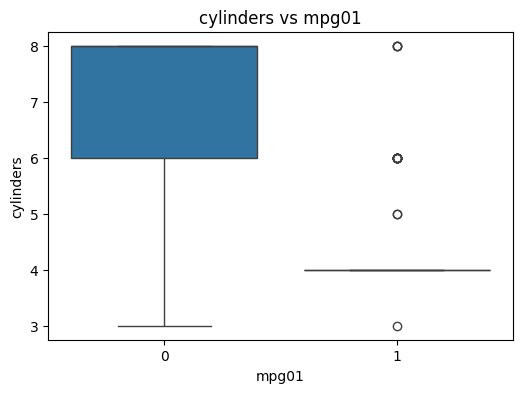

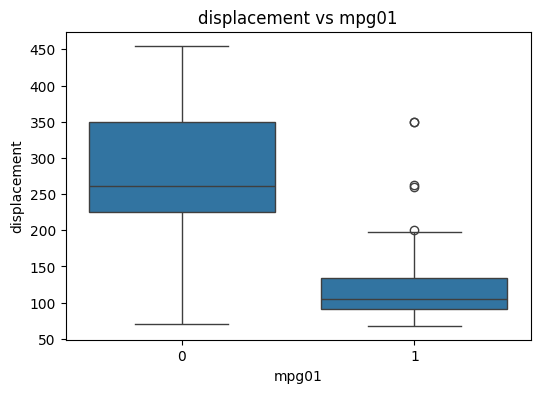

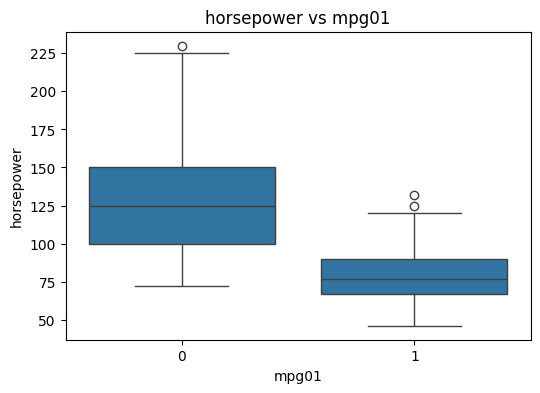

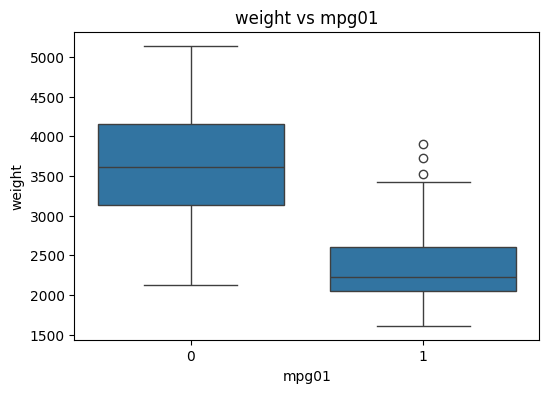

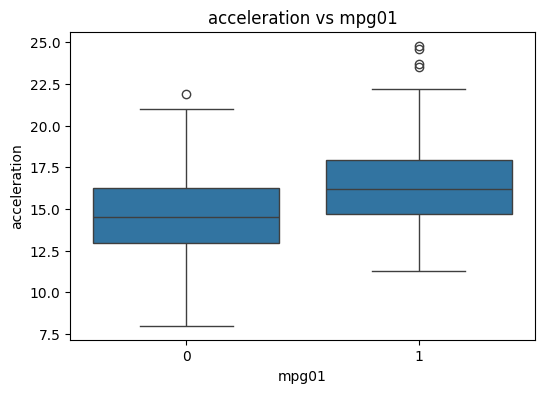

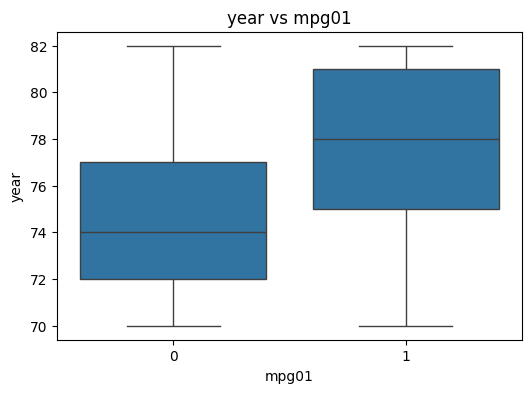

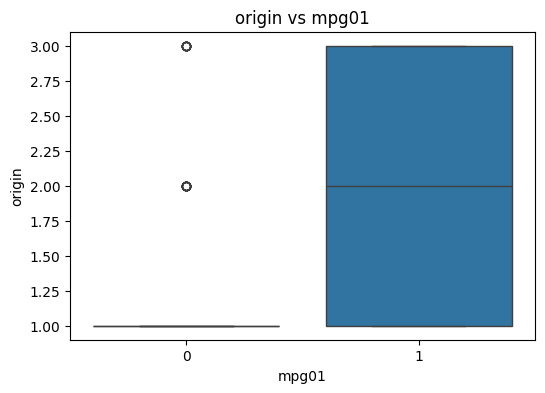

In [18]:
# (b)

import seaborn as sns
import matplotlib.pyplot as plt
sns.pairplot(auto, vars=["displacement", "horsepower", "weight", "acceleration"], hue="mpg01")
plt.show()
features = ["cylinders", "displacement", "horsepower", "weight", "acceleration", "year", "origin"]
for feature in features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x="mpg01", y=feature, data=auto)
    plt.title(f"{feature} vs mpg01")
    plt.show()


In [19]:
# From the scatterplots and boxplots:
# - Cars with mpg01 = 1 (high mpg) clearly have much lower displacement, horsepower, and weight.
# - Cars with mpg01 = 0 (low mpg) tend to have larger engines, higher horsepower, and greater weight.
# - The number of cylinders also differs strongly: most high-mpg cars have 4 cylinders, while low-mpg cars often have 6–8.
# - The "year" variable also shows a positive trend — newer cars tend to have higher mpg.
# - Acceleration and origin show weaker separation, though some tendency is visible.
# Therefore, the variables that seem most useful for predicting mpg01 are:
# displacement, horsepower, weight, cylinders, and year.

In [ ]:
# (c)

from sklearn.model_selection import train_test_split

X = auto.drop(columns=["mpg", "name", "mpg01"])
y = auto["mpg01"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.5, random_state=22)

print("Training set size:", X_train.shape)
print("Test set size:", X_test.shape)

Training set size: (196, 8)
Test set size: (196, 8)


In [ ]:
# (d)
# Perform Linear Discriminant Analysis (LDA) using predictors most associated with mpg01

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score

predictors = ["displacement", "horsepower", "weight", "cylinders", "year"]

lda = LinearDiscriminantAnalysis()
lda.fit(X_train[predictors], y_train)

y_pred_lda = lda.predict(X_test[predictors])

test_error_lda = 1 - accuracy_score(y_test, y_pred_lda)

print("LDA Test Error Rate:", test_error_lda)

LDA Test Error Rate: 0.08673469387755106


In [ ]:
# (e)
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
qda = QuadraticDiscriminantAnalysis()
qda.fit(X_train[predictors], y_train)

y_pred_qda = qda.predict(X_test[predictors])

test_error_qda = 1 - accuracy_score(y_test, y_pred_qda)

print("QDA Test Error Rate:", test_error_qda)

QDA Test Error Rate: 0.1071428571428571


In [23]:
# (f)

from sklearn.linear_model import LogisticRegression

log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train[predictors], y_train)

y_pred_log = log_reg.predict(X_test[predictors])

test_error_log = 1 - accuracy_score(y_test, y_pred_log)

print("Logistic Regression Test Error Rate:", test_error_log)

Logistic Regression Test Error Rate: 0.08163265306122447


In [24]:
# (g)

from sklearn.naive_bayes import GaussianNB
nb = GaussianNB()
nb.fit(X_train[predictors], y_train)

y_pred_nb = nb.predict(X_test[predictors])

test_error_nb = 1 - accuracy_score(y_test, y_pred_nb)

print("Naive Bayes Test Error Rate:", test_error_nb)

Naive Bayes Test Error Rate: 0.1071428571428571


In [ ]:
# (h)
# LDA Test Error Rate: 0.087
# QDA Test Error Rate: 0.107
# Logistic Regression Test Error Rate: 0.082
# Naive Bayes Test Error Rate: 0.107
#
# The Logistic Regression model performs the best with the lowest test error (around 8.2%),
# followed closely by LDA (8.7%). QDA and Naive Bayes perform slightly worse (both around 10.7%).
#
# I would therefore prefer the Logistic Regression model because it provides the best generalization
# performance on this dataset and makes fewer assumptions than LDA/QDA about the normality of predictors.
#
# However, choosing a model based only on one random train/test split can be misleading.
# The results may vary depending on how the data were split.
# To make a more robust decision, cross-validation should be used to estimate
# the average test error across multiple random splits.

In [ ]:
#question5-a
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import train_test_split

default = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-Default.csv")

import numpy as np
np.random.seed(22)

default["default_binary"] = (default["default"] == "Yes").astype(int)

X = default[["income", "balance"]]
y = default["default_binary"]
X = sm.add_constant(X)

logit_model = sm.Logit(y, X).fit()
print(logit_model.summary())

Optimization terminated successfully.
         Current function value: 0.078948
         Iterations 10
                           Logit Regression Results                           
Dep. Variable:         default_binary   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9997
Method:                           MLE   Df Model:                            2
Date:                Wed, 29 Oct 2025   Pseudo R-squ.:                  0.4594
Time:                        15:19:09   Log-Likelihood:                -789.48
converged:                       True   LL-Null:                       -1460.3
Covariance Type:            nonrobust   LLR p-value:                4.541e-292
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.5405      0.435    -26.544      0.000     -12.393     -10.688
income      2.081e-05   4.99

In [28]:
# Intercept (const):  -11.5405
# income:              0.0000208
# balance:             0.0056
#
# Interpretation:
# Both income and balance are statistically significant (p < 0.001).
# The positive coefficient for balance indicates that as balance increases,
# the probability of default increases.
# The small positive coefficient for income suggests that higher income
# slightly increases the probability of default, although the effect is minimal.
#
# The model converged successfully with a pseudo R² of 0.459, 
# indicating that balance is a strong predictor of default.

In [ ]:
# (b)

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

# i. 
X = default[["income", "balance"]]
y = default["default_binary"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.3, random_state=42
)
# ii.
log_reg_val = LogisticRegression(max_iter=1000)
log_reg_val.fit(X_train, y_train)
# iii.
y_prob = log_reg_val.predict_proba(X_valid)[:, 1]
y_pred = (y_prob > 0.5).astype(int)
# iv.
val_error = 1 - accuracy_score(y_valid, y_pred)
print("Validation Set Error Rate:", val_error)

Validation Set Error Rate: 0.026666666666666616


In [30]:
# The validation set approach yielded a test (validation) error rate of approximately 0.0267,
# meaning the model misclassifies about 2.7% of the observations in the validation set.
# This indicates that the logistic regression model using income and balance performs well
# in predicting default, with balance being the dominant predictor.
# However, since this estimate depends on one random 70/30 split,
# the exact error rate may vary with a different random seed or split.
# To obtain a more stable estimate of test error, cross-validation would be preferred.

In [ ]:
# (c)
# Repeat the validation set approach using three different random splits
# with random_states = 2, 6, and 9

error_rates = []

for seed in [2, 6, 9]:
    # Split the data (70% training, 30% validation)
    X_train, X_valid, y_train, y_valid = train_test_split(
        X, y, test_size=0.3, random_state=seed
    )

    # Fit logistic regression
    log_reg_model = LogisticRegression(max_iter=1000)
    log_reg_model.fit(X_train, y_train)

    # Predict probabilities and classify
    y_prob = log_reg_model.predict_proba(X_valid)[:, 1]
    y_pred = (y_prob > 0.5).astype(int)

    # Compute validation error
    val_error = 1 - accuracy_score(y_valid, y_pred)
    error_rates.append(val_error)

    print(f"Random state {seed} - Validation Set Error Rate: {val_error:.4f}")

Random state 2 - Validation Set Error Rate: 0.0237
Random state 6 - Validation Set Error Rate: 0.0247
Random state 9 - Validation Set Error Rate: 0.0217


In [32]:
# Comment:
# The validation set error rates are all very similar (around 2–2.5%), 
# which suggests that the logistic regression model is stable across 
# different random splits of the data.
# This consistency indicates that the model generalizes well 
# and that the estimated test error is not highly sensitive to 
# how the training and validation sets are chosen.
# Small variations between the error rates are expected 
# because each random split slightly changes which observations 
# are used for training and validation.

In [35]:
# (d)
default["student_dummy"] = (default["student"] == "Yes").astype(int)

X = default[["income", "balance", "student_dummy"]]
y = default["default_binary"]
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.3, random_state=42
)
log_reg_student = LogisticRegression(max_iter=1000)
log_reg_student.fit(X_train, y_train)
y_prob_student = log_reg_student.predict_proba(X_valid)[:, 1]
y_pred_student = (y_prob_student > 0.5).astype(int)

val_error_student = 1 - accuracy_score(y_valid, y_pred_student)

print("Validation Set Error Rate (with student dummy):", val_error_student)

Validation Set Error Rate (with student dummy): 0.026666666666666616


In [ ]:
# Comment
# Including the dummy variable for student does not significantly change the test (validation) error rate
# compared to the earlier model that used only income and balance (which was also about 0.0267).
# This indicates that the student variable adds little additional predictive power
# beyond what is already captured by income and balance.
# The balance variable remains the strongest predictor of default, and adding the student dummy
# neither improves nor harms the model’s generalization performance in any meaningful way.